In [1]:
import glob
import os

import numpy as np
import cv2
import matplotlib.pyplot as plt
from tqdm import tqdm

import sys
sys.path.append("../objectdetectionmetrics/")
from metricsevaluator import MetricsEvaluator

In [2]:
model_path = "/home/klymy/projects/cp-core/models/obj-det/yolov7-tiny-deploy-pg.onnx"

INPUT_WIDTH = 640
INPUT_HEIGHT = 640
CONFIDENCE_THRESHOLD = 0.4

NMS_THRESHOLD = 0.45

classes = ["table", "chair", "laptop"]

In [3]:
def post_process(input_image, outputs, conf_th=CONFIDENCE_THRESHOLD, nms_th=NMS_THRESHOLD):
    ratioh = input_image.shape[0] / INPUT_HEIGHT
    ratiow = input_image.shape[1] / INPUT_WIDTH

    confidences = []
    boxes = []
    class_ids = []

    for pdata in outputs:
        box_score = pdata[4]
        if box_score <= conf_th:
            continue
        scores = pdata[5:]
        classIdPoint = np.argmax(scores)
        max_class_socre = scores[classIdPoint]
        max_class_socre *= box_score

        if max_class_socre <= conf_th:
            continue

        cx = pdata[0] * ratiow
        cy = pdata[1] * ratioh
        w = pdata[2] * ratiow
        h = pdata[3] * ratioh

        left = int(cx - 0.5 * w);
        top = int(cy - 0.5 * h);

        confidences.append(max_class_socre);
        boxes.append((left, top, int(w), int(h)))
        class_ids.append(classIdPoint)
    
    indices = cv2.dnn.NMSBoxes(boxes, confidences, conf_th, nms_th)
    # for i in indices:
    #     box = boxes[i]
    #     left = box[0]
    #     top = box[1]
    #     width = box[2]
    #     height = box[3]             
    #     # Draw bounding box.             
    #     cv2.rectangle(input_image, (left, top), (left + width, top + height), BLUE, 3*THICKNESS)
    #     # Class label.                      
    #     label = "{}:{:.2f}".format(classes[class_ids[i]], confidences[i])             
    #     # Draw label.             
    #     draw_label(input_image, label, left, top)
    return np.array(boxes)[indices], np.array(class_ids)[indices], np.array(confidences)[indices]

In [41]:
data = "datasets/v2_batch6/merged_furniture_table_chair_gray"
img_folder = os.path.join(data, "images", "val")
tst_img_paths = [os.path.join(img_folder, i) for i in os.listdir(img_folder)]
len(tst_img_paths)

292

In [42]:
model = cv2.dnn.readNet(model_path)

In [48]:
classes_yolov8 = ["chair", "table"]

data = "datasets/v2_batch6/merged_furniture_table_chair"

img_folder = os.path.join(data, "images", "val")
tst_img_paths = [os.path.join(img_folder, i) for i in os.listdir(img_folder)]

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(INPUT_WIDTH, INPUT_HEIGHT),
    outpath="."
)

for label_pth in os.listdir(os.path.join(data, "labels", "val")):
    img_name = label_pth.split(".")[0]

    with open(os.path.join(data, "labels", "val", label_pth), "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
        if c > 1:
            continue
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name=classes_yolov8[int(c)],
            bbox=[x_c, y_c, w, h]
        )
    # break

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    
    img = cv2.imread(img_pth)
    h, w, _ = img.shape
    blob = cv2.dnn.blobFromImage(img, 1 / 255.0, (INPUT_WIDTH, INPUT_HEIGHT), (0,0,0), False, crop=False)
    # set input blob for the network
    model.setInput(blob)
    # Run the forward pass to get output of the output layers.
    outputs = model.forward(model.getUnconnectedOutLayersNames())
    res = post_process(img.copy(), outputs[0][0], CONFIDENCE_THRESHOLD, NMS_THRESHOLD)

    for box, cl, conf in zip(*res):
        if cl > 1:
            continue
        evaluator.add_det_box(
            img_path=img_name,
            class_name=classes[cl],
            bbox=(box + [box[2] / 2, box[3] / 2, 0, 0]) / [w, h, w, h],
            confidence=conf
        )
    # break

results = evaluator.eval_conf_vals(0.5)

for result in results:
    precision = result["total TP"] / (result["total TP"] + result["total FP"])
    recall = result["total TP"] / (result["total positives"])

    f_score = 2 * precision * recall / (precision + recall)
    print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

  0%|          | 0/292 [00:00<?, ?it/s]

100%|██████████| 292/292 [00:39<00:00,  7.42it/s]


chair: P = 0.757. R = 0.610. F1 = 0.676. AP = 0.553
table: P = 0.485. R = 0.488. F1 = 0.487. AP = 0.322


In [49]:
classes_yolov8 = ["chair", "table"]

data = "datasets/v2_batch6/merged_furniture_table_chair_gray"

img_folder = os.path.join(data, "images", "val")
tst_img_paths = [os.path.join(img_folder, i) for i in os.listdir(img_folder)]

# init evaluator
evaluator = MetricsEvaluator(
    is_relative_coordinates=True,
    is_xywh_coordinates=True,
    img_size=(INPUT_WIDTH, INPUT_HEIGHT),
    outpath="."
)

for label_pth in os.listdir(os.path.join(data, "labels", "val")):
    img_name = label_pth.split(".")[0]

    with open(os.path.join(data, "labels", "val", label_pth), "rt") as f:
        lines = f.readlines()
    
    for line in lines:
        c, x_c, y_c, w, h = [float(i) for i in line[:-1].split()][:5]
        if c > 1:
            continue
        
        evaluator.add_gt_box(
            img_path=img_name,
            class_name=classes_yolov8[int(c)],
            bbox=[x_c, y_c, w, h]
        )
    # break

for img_pth in tqdm(tst_img_paths):
    img_name = os.path.basename(img_pth).split(".")[0]
    
    img = cv2.imread(img_pth)
    h, w, _ = img.shape
    blob = cv2.dnn.blobFromImage(img, 1 / 255.0, (INPUT_WIDTH, INPUT_HEIGHT), (0,0,0), False, crop=False)
    # set input blob for the network
    model.setInput(blob)
    # Run the forward pass to get output of the output layers.
    outputs = model.forward(model.getUnconnectedOutLayersNames())
    res = post_process(img.copy(), outputs[0][0], CONFIDENCE_THRESHOLD, NMS_THRESHOLD)

    for box, cl, conf in zip(*res):
        if cl > 1:
            continue
        evaluator.add_det_box(
            img_path=img_name,
            class_name=classes[cl],
            bbox=(box + [box[2] / 2, box[3] / 2, 0, 0]) / [w, h, w, h],
            confidence=conf
        )
    # break

results = evaluator.eval_conf_vals(0.5)

for result in results:
    precision = result["total TP"] / (result["total TP"] + result["total FP"])
    recall = result["total TP"] / (result["total positives"])

    f_score = 2 * precision * recall / (precision + recall)
    print(f"{result['class']}: P = {precision:.03f}. R = {recall:.03f}. F1 = {f_score:.03f}. AP = {result['AP']:.03f}")

  1%|          | 2/292 [00:00<00:36,  8.03it/s]

100%|██████████| 292/292 [00:37<00:00,  7.70it/s]


chair: P = 0.757. R = 0.610. F1 = 0.676. AP = 0.551
table: P = 0.487. R = 0.502. F1 = 0.494. AP = 0.332


In [43]:
tst_img_paths = sorted(tst_img_paths)

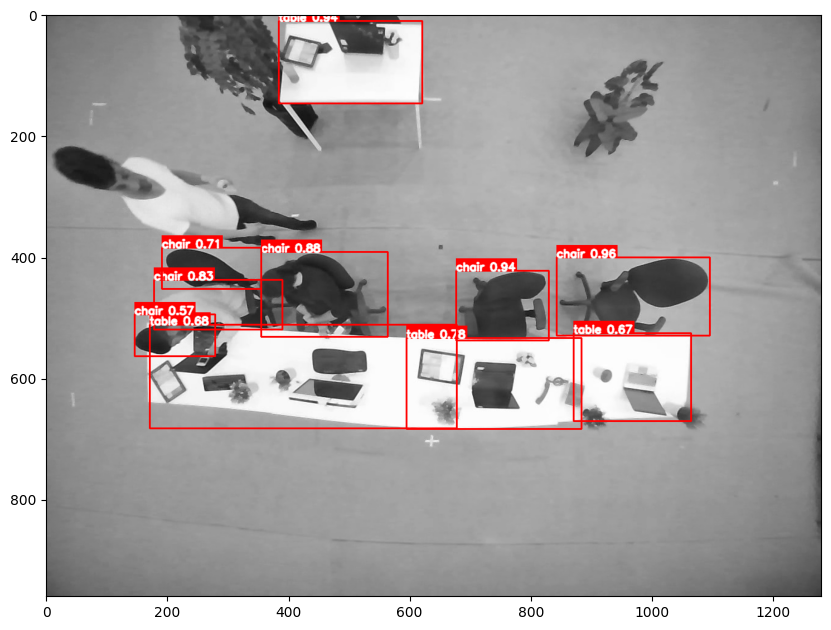

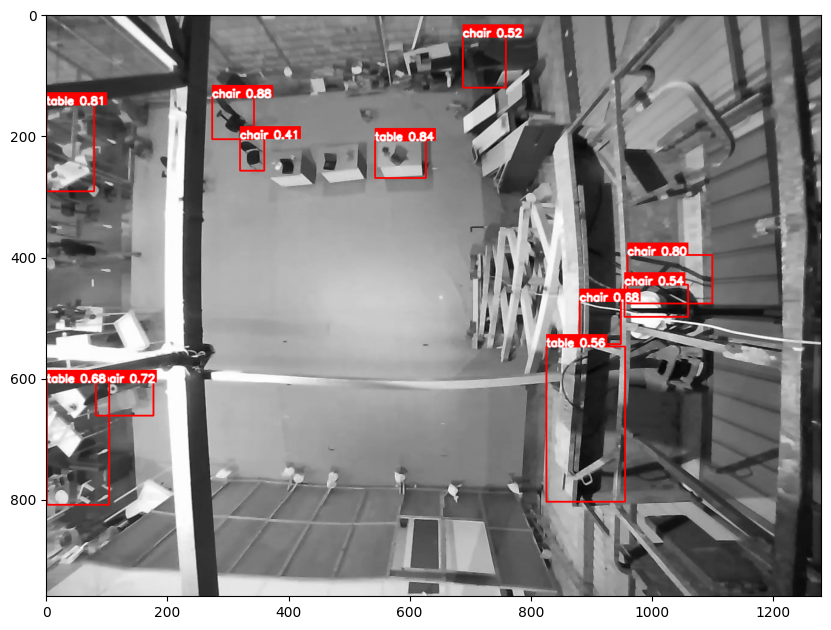

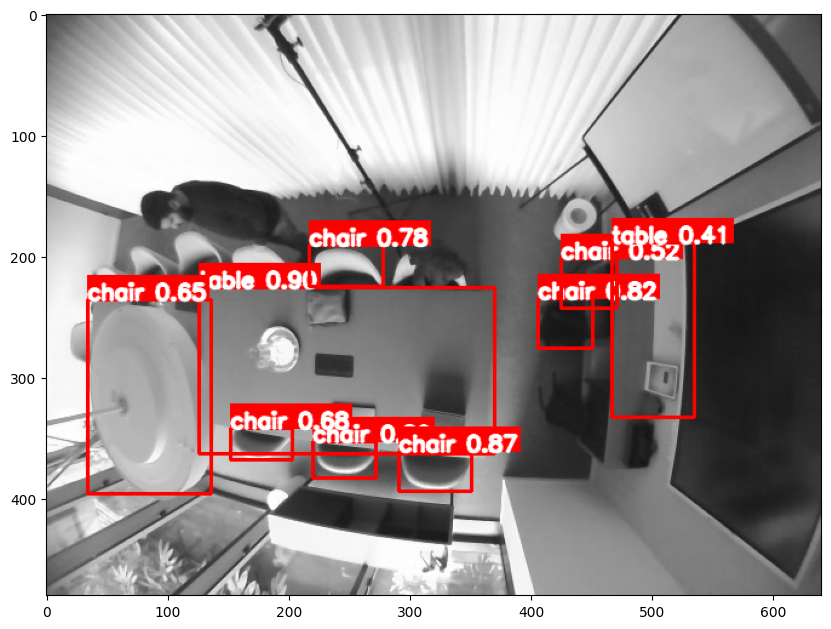

In [46]:
# font 
font = cv2.FONT_HERSHEY_SIMPLEX 
  
# fontScale 
fontScale = 0.6
  
# Line thickness of 2 px 
thickness = 2

for img_pth in tst_img_paths[:3]:
    img = cv2.imread(img_pth)

    blob = cv2.dnn.blobFromImage(img, 1 / 255.0, (INPUT_WIDTH, INPUT_HEIGHT), (0,0,0), False, crop=False)

    # set input blob for the network
    model.setInput(blob)

    # Run the forward pass to get output of the output layers.
    outputs = model.forward(model.getUnconnectedOutLayersNames())

    res = post_process(img.copy(), outputs[0][0])
    # print(res[0])

    tmp = img.copy()
    for idx, box in enumerate(res[0]):
        if res[1][idx] > 1:
            continue
        cv2.rectangle(tmp, box[:2].astype(int), box[:2].astype(int) + box[2:].astype(int), (255, 0, 0), 2)
        cv2.rectangle(tmp, box[:2].astype(int) - [0, 20], box[:2].astype(int) + [100, 0], (255, 0, 0), -1)
        
        org = box[:2].astype(int)
        
        cv2.putText(tmp, f"{classes[res[1][idx]]} {res[2][idx]:.02f}", org, font, fontScale, (255, 255, 255), thickness, cv2.LINE_AA) 

    plt.figure(figsize=(10, 10))
    plt.imshow(tmp);